# Breakout Room #4 — La curva Qini: ¿el modelo ordena de verdad?

**Objetivo:** construir la curva Qini y la tabla de deciles para comparar dos formas de
ordenar a los 14,000 clientes del experimento — por **riesgo/churn** y por **uplift
(T-learner)** — y ver cuál de las dos sirve de verdad para decidir a quién contactar.

Esta vez separamos los datos en dos partes: **entrenamiento** (para que los modelos
aprendan) y **prueba** (para evaluarlos con datos que nunca vieron — la misma idea de "las
dos ventanas" del Breakout 2, pero aplicada a modelos en vez de a fechas).

Donde dice **`# TODO`** hay algo para que ustedes completen.


In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/uplift_experiment.csv")
FEATURES = ["recency_days", "frequency", "monetary", "email_open_rate"]

train, test = train_test_split(df, test_size=0.30, random_state=42, stratify=df["treatment_group"])
print(f"Entrenamiento: {len(train):,} clientes · Prueba: {len(test):,} clientes (el modelo nunca los ve)")


Entrenamiento: 9,800 clientes · Prueba: 4,200 clientes (el modelo nunca los ve)


## Paso 1 — entrenen los dos modelos (solo con datos de ENTRENAMIENTO)

- **`modelo_riesgo`**: un modelo de churn normal y corriente. No sabe nada de tratamiento/control
  — mezcla a todos los clientes de entrenamiento y aprende a predecir quién NO va a responder
  (`churned = 1 - responded_90d`). Así funcionaría un modelo de churn tradicional, el mismo tipo
  que construyeron en el Breakout 2.
- **`modelo_tratado`** y **`modelo_control`**: el T-learner de siempre (Breakout 3), entrenado
  solo con las filas de entrenamiento.


In [4]:
# TODO: entrenen modelo_riesgo prediciendo "churned" (1 - responded_90d) usando SOLO train

# Crear variable churned: 1 si no respondió, 0 si respondió
train = train.copy()
train["churned"] = 1 - train["responded_90d"]

# Entrenar modelo de riesgo/churn utilizando únicamente train
modelo_riesgo = LogisticRegression(max_iter=1000)

modelo_riesgo.fit(
    train[FEATURES],
    train["churned"]
)

tratados = df[df["treatment_group"] == "treatment"]
control = df[df["treatment_group"] == "control"]

modelo_tratado = LogisticRegression(max_iter=1000)
modelo_tratado.fit(
    tratados[FEATURES],
    tratados["responded_90d"]
)

modelo_control = LogisticRegression(max_iter=1000)
modelo_control.fit(
    control[FEATURES],
    control["responded_90d"]
)



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

## Paso 2 — puntúen el conjunto de PRUEBA (el que ningún modelo vio)

Igual que en el Breakout 3: le preguntan a los modelos sobre todos los clientes de prueba,
tratados y de control por igual.


In [7]:
test = test.copy()
X_test = test[FEATURES]

# TODO: calculen las tres probabilidades sobre el conjunto de prueba
# Probabilidad de churn para cada cliente
test["prob_churn"] = modelo_riesgo.predict_proba(X_test)[:, 1]

# Probabilidad de responder si el cliente recibe tratamiento
test["p_tratado"] = modelo_tratado.predict_proba(X_test)[:, 1]

# Probabilidad de responder si el cliente queda en control
test["p_control"] = modelo_control.predict_proba(X_test)[:, 1]

# Uplift estimado
test["uplift_estimado"] = (
    test["p_tratado"] - test["p_control"]
)


## Paso 3 — la curva Qini

Para cada corte N (del 2.5% al 100% de la base de prueba, ordenada de "mejor" a "peor" según el
modelo), midan:

```
ganancia(N) = (tasa de respuesta de los tratados en el top N  −  tasa de respuesta del control en el top N)  ×  N
```

Esa es la curva — compara contra la diagonal del azar. El **coeficiente Qini** es, sencillamente,
el área entre la curva del modelo y la diagonal del azar: entre más área (más arriba de la
diagonal), mejor ordena el modelo.


In [8]:
def curva_qini(test_df, score_col, steps=40):
    orden = test_df.sort_values(score_col, ascending=False).reset_index(drop=True)
    es_tratado = (orden["treatment_group"] == "treatment").values
    respondio = orden["responded_90d"].values

    acumulado_tratados = np.cumsum(np.where(es_tratado, respondio, 0))
    acumulado_control = np.cumsum(np.where(~es_tratado, respondio, 0))
    n_tratados_acum = np.cumsum(es_tratado)
    n_control_acum = np.cumsum(~es_tratado)

    n = len(orden)
    xs, ys = [0.0], [0.0]
    for i in np.linspace(1, n, steps).astype(int):
        nt, nc = n_tratados_acum[i - 1], n_control_acum[i - 1]
        tasa_t = acumulado_tratados[i - 1] / nt if nt > 0 else 0
        tasa_c = acumulado_control[i - 1] / nc if nc > 0 else 0
        xs.append(i / n)
        ys.append((tasa_t - tasa_c) * n)
    return np.array(xs), np.array(ys)


def coeficiente_qini(xs, ys):
    area_modelo = np.trapezoid(ys, xs)
    area_azar = np.trapezoid(np.linspace(0, ys[-1], len(xs)), xs)
    return (area_modelo - area_azar) / len(test)


xs_uplift, ys_uplift = curva_qini(test, "uplift_estimado")
xs_riesgo, ys_riesgo = curva_qini(test, "prob_churn")

qini_uplift = coeficiente_qini(xs_uplift, ys_uplift)
qini_riesgo = coeficiente_qini(xs_riesgo, ys_riesgo)

print(f"Coeficiente Qini · modelo de uplift (T-learner): {qini_uplift:+.3f}")
print(f"Coeficiente Qini · modelo de riesgo (churn):      {qini_riesgo:+.3f}")


Coeficiente Qini · modelo de uplift (T-learner): +0.220
Coeficiente Qini · modelo de riesgo (churn):      +0.006


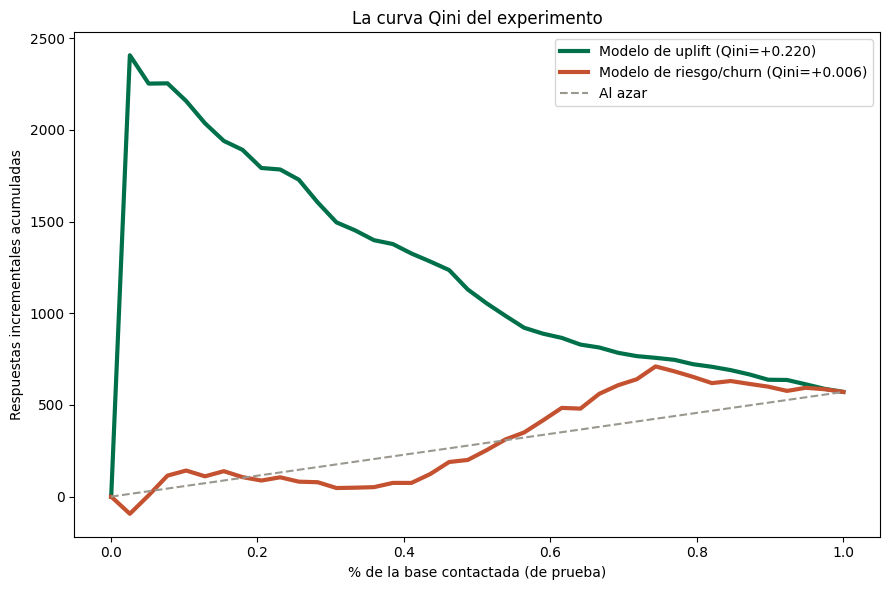

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(xs_uplift, ys_uplift, color="#00704A", linewidth=3, label=f"Modelo de uplift (Qini={qini_uplift:+.3f})")
ax.plot(xs_riesgo, ys_riesgo, color="#C4512F", linewidth=3, label=f"Modelo de riesgo/churn (Qini={qini_riesgo:+.3f})")
ax.plot([0, 1], [0, ys_uplift[-1]], color="#9A988E", linestyle="--", label="Al azar")
ax.set_xlabel("% de la base contactada (de prueba)")
ax.set_ylabel("Respuestas incrementales acumuladas")
ax.set_title("La curva Qini del experimento")
ax.legend()
plt.tight_layout()
plt.savefig("curva_qini.png", dpi=150)
plt.show()


## Paso 4 — la tabla de deciles: ¿el modelo ordena de verdad?

Dividan el conjunto de prueba en 10 deciles según `uplift_estimado` (decil 1 = uplift más alto
predicho). Para cada decil, comparen el uplift PREDICHO promedio contra el uplift REAL (tasa de
respuesta de tratados menos tasa de respuesta de control, DENTRO de ese decil).


In [10]:
test["decil"] = pd.qcut(test["uplift_estimado"], 10, labels=False, duplicates="drop")
test["decil"] = 9 - test["decil"]  # decil 1 = el de mayor uplift predicho

filas = []
for d in range(10):
    grp = test[test["decil"] == d]
    pred = grp["uplift_estimado"].mean()
    real_t = grp.loc[grp["treatment_group"] == "treatment", "responded_90d"].mean()
    real_c = grp.loc[grp["treatment_group"] == "control", "responded_90d"].mean()
    filas.append({"decil": d + 1, "uplift_predicho": round(pred, 3), "uplift_real": round(real_t - real_c, 3), "n": len(grp)})

tabla_deciles = pd.DataFrame(filas)
tabla_deciles


,decil,uplift_predicho,uplift_real,n
0,1,0.404,0.510,420
1,2,0.292,0.365,420
2,3,0.219,0.225,420
3,4,0.168,0.190,420
4,5,0.128,0.036,420
5,6,0.095,-0.027,420
6,7,0.068,0.046,420
7,8,0.046,0.052,420
8,9,0.024,0.019,420
9,10,-0.018,-0.001,420


## Para la Clase

1. ¿El coeficiente Qini del modelo de riesgo/churn es mayor, menor o parecido al del modelo de uplift? ¿Qué dice eso sobre usar un modelo de churn para decidir a quién contactar?

   El coeficiente Qini de riesgo es menor al del modelo uplift, lo que indica que usar el modelo de churn no ordena de forma correcta a los clientes que vale la pena contactar.

2. Miren la tabla de deciles: ¿hay algún decil donde lo predicho y lo real se alejan mucho? Con ~420 clientes por decil, ¿qué tan confiables son esos números?

   Si, en el decil 6 el predicho indicaba un valor de 0.095 y el real indicaba -0.27, a partir de este los demás deciles no estan ordenados. Aún asi, los primeros 5 deciles estan ordenados y con valores similares, por lo que representa correctamente los clientes que valen la pena contactar.

3. Si tuvieran que explicarle a alguien de negocio qué es el coeficiente Qini en una frase, ¿qué dirían?

   El coeficiente Qini mide que tan bien un modelo identifica a los clientes que realmente aportan valor al ser contactados.